# Numerical simulation 2: convection in a lake

**37EFM Environmental Fluid Mechanics, TU/e**

A lake of depth $H = 20$ m loses heat at its surface. The cooled surface water is denser than the water below and sinks: convection. GOTM represents this with its $k$-$\varepsilon$ closure, which here has to work in a flow driven by buoyancy rather than by shear.

Base configuration: `efmgotm/cases/lake.yaml`. The settings you will change are

| setting | key | sheet symbol |
|---|---|---|
| surface heat flux [W/m$^2$], negative = cooling | `surface.fluxes.heat.constant_value` | $Q$ |
| initial stratification, buoyancy frequency squared [s$^{-2}$] | `temperature.NN` | $N^2$ |
| wind stress [Pa] | `surface.fluxes.tx.constant_value` | $\tau_x$ |

The equation of state is linear with $\alpha = 2.6 \times 10^{-4}$ K$^{-1}$, $\rho_0 = 1000$ kg/m$^3$ and $c_p = 4.15 \times 10^3$ J/(kg K), the values on the sheet, so that the theoretical expressions can be compared with the model without conversion. The run covers 7 days with hourly output.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import efmgotm
from efmgotm import analysis
plt.rcParams['figure.dpi'] = 80
RUNS = 'runs'          # run directories are created here

## (a) No stratification, weak cooling

With $N^2 = 0$ and $Q = -0.05$ W/m$^2$, the convective layer is expected to deepen as $h = w_* t$ with the convective velocity $w_* = (\alpha g |Q| H / (\rho_0 c_p))^{1/3}$.

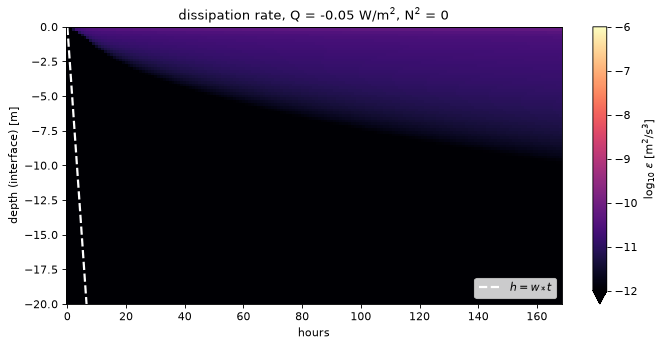

In [2]:
Q = -0.05
ds = efmgotm.run('lake', {'surface.fluxes.heat.constant_value': Q, 'temperature.NN': 0.0}, workdir=RUNS)
t = ds.seconds.values
h_theory = analysis.convective_depth_unstratified(t, Q, H=20)

fig, ax = plt.subplots(figsize=(10, 4.5))
np.log10(ds.eps).plot(ax=ax, x='hours', y='zi', cmap='magma', vmin=-12, vmax=-6, cbar_kwargs={'label': r'$\log_{10}\,\varepsilon$ [m$^2$/s$^3$]'})
ax.plot(ds.hours, -h_theory, 'w--', lw=2, label='$h = w_* t$')
ax.set_ylim(-20, 0); ax.legend(loc='lower right'); ax.set_title(f'dissipation rate, Q = {Q} W/m$^2$, N$^2$ = 0');

Now the same with $Q = -5$ W/m$^2$.

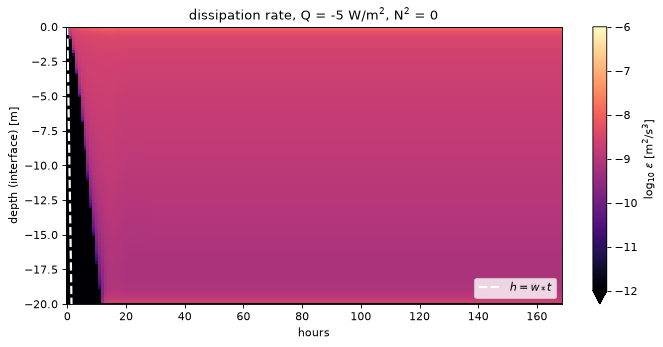

In [3]:
Q = -5
ds = efmgotm.run('lake', {'surface.fluxes.heat.constant_value': Q, 'temperature.NN': 0.0}, workdir=RUNS)
h_theory = analysis.convective_depth_unstratified(ds.seconds.values, Q, H=20)

fig, ax = plt.subplots(figsize=(10, 4.5))
np.log10(ds.eps).plot(ax=ax, x='hours', y='zi', cmap='magma', vmin=-12, vmax=-6, cbar_kwargs={'label': r'$\log_{10}\,\varepsilon$ [m$^2$/s$^3$]'})
ax.plot(ds.hours, -h_theory, 'w--', lw=2, label='$h = w_* t$')
ax.set_ylim(-20, 0); ax.legend(loc='lower right'); ax.set_title(f'dissipation rate, Q = {Q} W/m$^2$, N$^2$ = 0');

Profiles at a few times help to see what the colour map shows. Change the variable (`eps`, `tke`, `num`, `nuh`, `temp`) and the times.

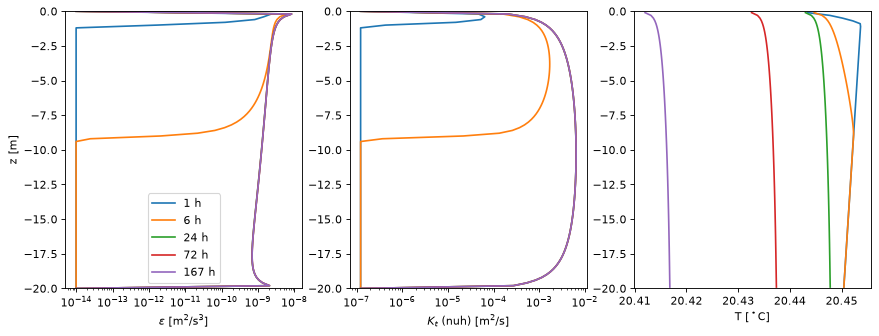

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(13, 4.5))
for hours in [1, 6, 24, 72, 167]:
    sel = ds.sel(time=ds.time[0] + np.timedelta64(hours, 'h'))
    axs[0].semilogx(sel.eps, sel.zi, label=f'{hours} h')
    axs[1].semilogx(sel.nuh, sel.zi)
    axs[2].plot(sel.temp, sel.z)
axs[0].set_xlabel(r'$\varepsilon$ [m$^2$/s$^3$]'); axs[0].set_ylabel('z [m]'); axs[0].legend()
axs[1].set_xlabel(r'$K_t$ (nuh) [m$^2$/s]')
axs[2].set_xlabel('T [$^\circ$C]')
for ax in axs: ax.set_ylim(-20, 0)

## (b) Stratification and cooling

With an initial stratification $N^2 = 10^{-4}$ s$^{-2}$ and $Q = -5$ W/m$^2$ the sheet gives the convective depth

$$h = \sqrt{\frac{6\,\alpha g |Q|\, t}{\rho_0 c_p N^2}}.$$

This is the result of Cushman-Roisin (Section 7.4), who assumes that the potential energy of the water column is unchanged by the convection, which puts a temperature jump of $\Gamma h / 3$ at the base of the convective layer. If the cooled layer simply took the temperature of the water at its base (encroachment, no jump), the 6 would be a 2. Plot the stratification and the temperature against $\sqrt{t}$, so that both laws are straight lines, and compare. The function `analysis.convective_depth_stratified` has a `factor` argument (default 6).

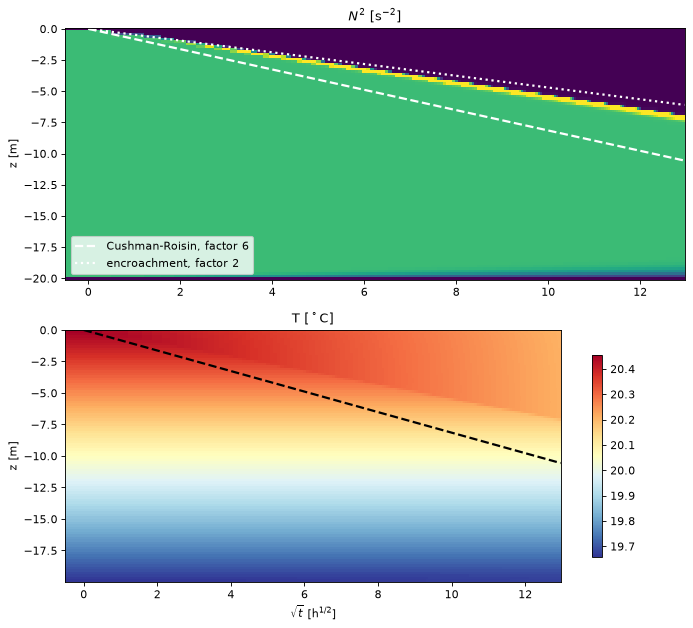

In [5]:
Q, N2 = -5, 1e-4
ds = efmgotm.run('lake', {'surface.fluxes.heat.constant_value': Q, 'temperature.NN': N2}, workdir=RUNS)
t = ds.seconds.values
h_theory = analysis.convective_depth_stratified(t, Q, N2)
sqrt_hours = np.sqrt(ds.hours.values)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 9))
ax1.pcolormesh(sqrt_hours, ds.zi, ds.NN.T, cmap='viridis', vmin=0, vmax=1.5 * N2, shading='nearest')
ax1.plot(sqrt_hours, -h_theory, 'w--', lw=2, label='Cushman-Roisin, factor 6')
ax1.plot(sqrt_hours, -analysis.convective_depth_stratified(t, Q, N2, factor=2), 'w:', lw=2, label='encroachment, factor 2')
ax1.set_ylabel('z [m]'); ax1.set_title('$N^2$ [s$^{-2}$]'); ax1.legend(loc='lower left')
pc = ax2.pcolormesh(sqrt_hours, ds.z, ds.temp.T, cmap='RdYlBu_r', shading='nearest')
ax2.plot(sqrt_hours, -h_theory, 'k--', lw=2)
ax2.set_xlabel(r'$\sqrt{t}$ [h$^{1/2}$]'); ax2.set_ylabel('z [m]'); ax2.set_title('T [$^\circ$C]')
fig.colorbar(pc, ax=ax2, shrink=0.8);

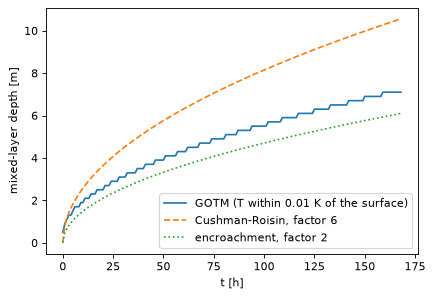

In [6]:
# the mixed-layer depth diagnosed from the temperature profile, against the theory
mld = analysis.mixed_layer_depth(ds, 'temp', threshold=0.01)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(ds.hours, mld, label='GOTM (T within 0.01 K of the surface)')
ax.plot(ds.hours, h_theory, '--', label='Cushman-Roisin, factor 6')
ax.plot(ds.hours, analysis.convective_depth_stratified(t, Q, N2, factor=2), ':', label='encroachment, factor 2')
ax.set_xlabel('t [h]'); ax.set_ylabel('mixed-layer depth [m]'); ax.legend();

Profiles of temperature and of $N^2$ at a few times show how the model erodes the stratification. Do you see an overshoot, a layer that is colder than the water below it?

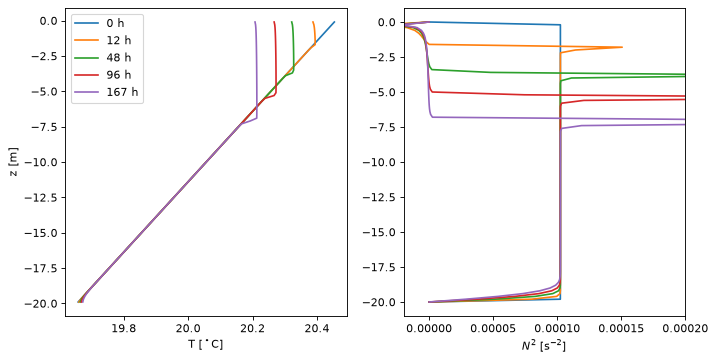

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
for hours in [0, 12, 48, 96, 167]:
    sel = ds.sel(time=ds.time[0] + np.timedelta64(hours, 'h'))
    ax1.plot(sel.temp, sel.z, label=f'{hours} h')
    ax2.plot(sel.NN, sel.zi)
ax1.set_xlabel('T [$^\circ$C]'); ax1.set_ylabel('z [m]'); ax1.legend()
ax2.set_xlabel('$N^2$ [s$^{-2}$]'); ax2.set_xlim(-0.2 * N2, 2 * N2);